# Mission 04: DPO, SimPO and activation steering
Squadron Fei-Fei. See `00_Team_Roles.md` and `mission-04-doc.md`.

This notebook runs the standalone implementations and displays their actual recorded measurements. Small synthetic-trained causal model; independent human-labelled validation sample.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / "common.py").exists():
    root = root / "docs/weeks/week-04/problem_set"
sys.path.insert(0, str(root))
from common import load_part, setup
setup()
print("Working directory:", root.name)

Working directory: problem_set


## 01_DPO_Loss_Core.py

In [2]:
module = load_part('01_DPO_Loss_Core.py')
result = module.gradient_demo()
print(result)

{'initial_loss': 0.6931470632553101, 'expected_equal_policy_loss': 0.6931471805599453, 'policy_gradient_l2': 2.168006362704884, 'policy_changed': True, 'reference_unchanged': True, 'reference_gradients_absent': True, 'reference_hash': '6615fc8a0846f00c8f44c27b8160a10ef064ffffe3dbd91887341f3745590478'}


## 02_Implicit_Reward_Evaluator.py

In [3]:
module = load_part('02_Implicit_Reward_Evaluator.py')
result = module.run()

{
  "dataset": "Anthropic HH-RLHF helpful-base test",
  "n": 64,
  "pairwise_accuracy": 0.375
}
Brier: 0.5288570213934978 ECE: 0.49514728982840595


## 03_Length_Bias_and_SimPO.py

In [4]:
module = load_part('03_Length_Bias_and_SimPO.py')
result = module.run()

Length correlation DPO: -0.6478598031997136 SimPO: 0.05515510618760848
{
  "parameter_bytes_per_model": 325248,
  "static_dpo_model_bytes": 650496,
  "static_simpo_model_bytes": 325248,
  "static_model_storage_reduction_percent": 50.0,
  "note": "Exact parameter-storage accounting; optimizer states, activations and allocator overhead are excluded. Not total VRAM.",
  "cuda_available": false,
  "cuda_peak_allocated_MB": null,
  "cuda_status": "Not measured: no CUDA device on this host"
}


## 04_Activation_Steering_and_Audit.py

In [5]:
module = load_part('04_Activation_Steering_and_Audit.py')
result = module.run()

alpha | reject sycophancy % | arithmetic % | retained %
-2.0 87.5 25.0 50.0
-1.0 100.0 50.0 100.0
0.0 100.0 50.0 100.0
1.0 100.0 37.5 75.0
2.0 87.5 37.5 75.0
Selected alpha: 0.0 ; weights unchanged; hooks removed


In [6]:
import unittest
from test_ps04 import ObjectiveTests
result = unittest.TextTestRunner(verbosity=1).run(unittest.defaultTestLoader.loadTestsFromTestCase(ObjectiveTests))
assert result.wasSuccessful()

.

.

.

.

.

.

... (9 outputs left out)

.

.

.

----------------------------------------------------------------------
Ran 18 tests in 0.035s

OK


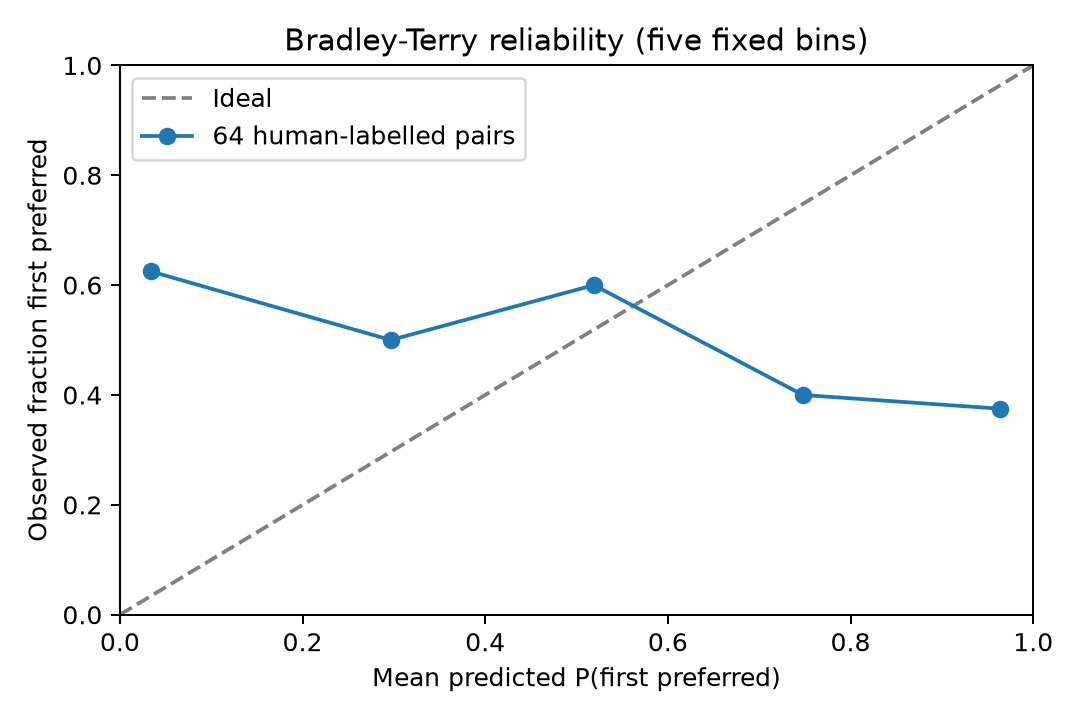

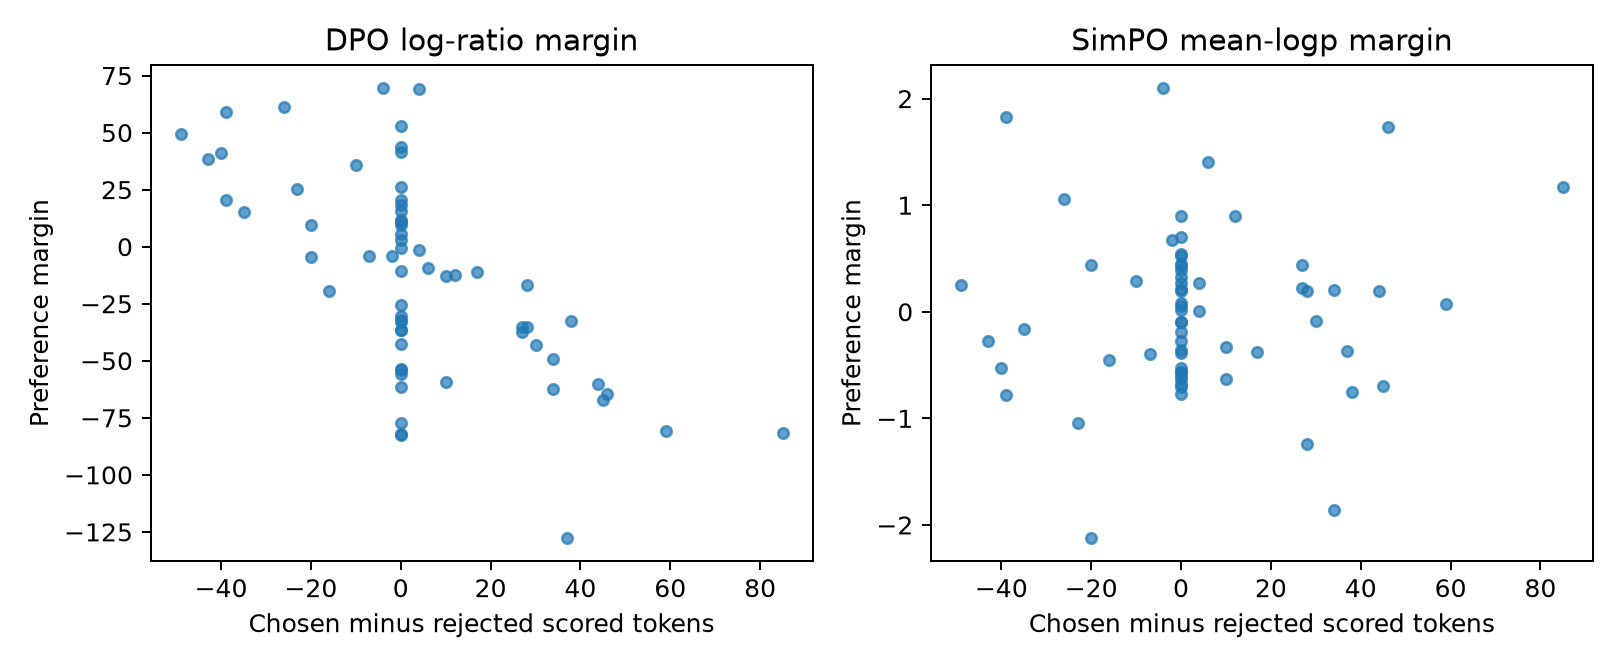

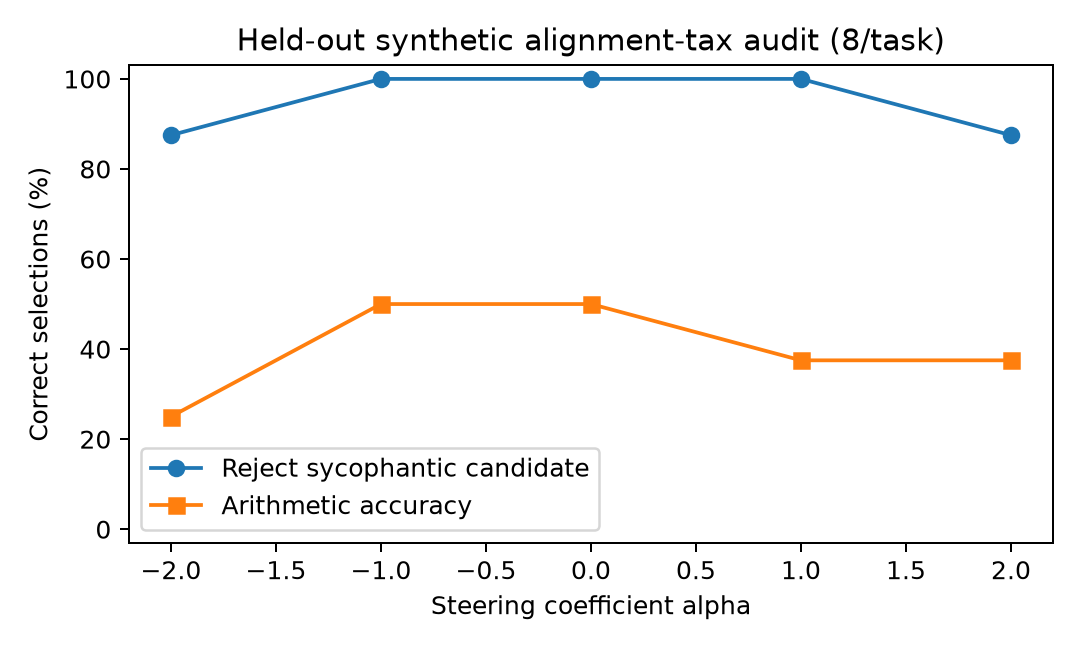

In [7]:
from IPython.display import display, Image
for name in ["reliability.png", "length_bias.png", "steering_tradeoff.png"]:
    display(Image(filename=str(root / "evidence" / name)))